# Capstone Project 1: Working with NumPy Matrices
## Exploratory Analysis of Adult NHANES Body Measurements

**Objective.** This notebook compares adult male and female body measurements using NumPy, Matplotlib, and pandas/seaborn for visualisation and correlation analysis. It examines weight distributions, body mass index (BMI), standardised measurements, and two waist-based ratios.

**Dataset.** The two CSV excerpts are from the teaching-data repository and contain seven measurements per participant. The notebook downloads the files directly from the repository when run with an internet connection.

**Reproducibility note.** Each analysis section includes a short explanation before the code and a concise interpretation after it. Numerical findings are generated from the downloaded data when the notebook is executed; interpretations should be checked against the printed output.

## 1. Import libraries and load the data

The first code cell imports the libraries used throughout the notebook. It then downloads the male and female CSV files and loads them as NumPy arrays. The expected seven columns are weight, standing height, upper arm length, upper leg length, arm circumference, hip circumference, and waist circumference.

In [1]:
# 1. Import libraries and load the data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from urllib.request import urlretrieve
from io import StringIO

# Dataset URL
base_url = (
    "https://raw.githubusercontent.com/gagolews/"
    "teaching-data/master/marek/"
)

male_file = "nhanes_adult_male_bmx_2020.csv"
female_file = "nhanes_adult_female_bmx_2020.csv"

# Download and check the files
for filename in [male_file, female_file]:
    urlretrieve(base_url + filename, filename)
    print(f"Downloaded: {filename}")

# Load the CSV files
def load_body_data(filename):
    text = Path(filename).read_text(
        encoding="utf-8-sig"
    )

    # Display the beginning if the header is not found
    lines = text.splitlines()

    start = next(
        (
            i for i, line in enumerate(lines)
            if "BMXWT" in line
        ),
        None
    )

    if start is None:
        print(f"\nBeginning of {filename}:")
        print(text[:500])
        raise ValueError(
            f"BMXWT header not found in {filename}"
        )

    # Read data starting from the header
    df = pd.read_csv(
        StringIO("\n".join(lines[start:])),
        skipinitialspace=True
    )

    # Required measurement columns
    columns = [
        "BMXWT",
        "BMXHT",
        "BMXARML",
        "BMXLEG",
        "BMXARMC",
        "BMXHIP",
        "BMXWAIST"
    ]

    # Clean column names
    df.columns = df.columns.astype(str).str.strip()

    # Check that all required columns exist
    missing = [
        col for col in columns
        if col not in df.columns
    ]

    if missing:
        raise ValueError(
            f"Missing columns: {missing}. "
            f"Found columns: {list(df.columns)}"
        )

    # Convert measurements to numbers
    df = df[columns].apply(
        pd.to_numeric, errors="coerce"
    )

    # Remove rows with missing values
    df = df.dropna()

    return df.to_numpy(dtype=float)


# Load male and female matrices
male = load_body_data(male_file)
female = load_body_data(female_file)

# Measurement names
column_names = [
    "Weight (kg)",
    "Height (cm)",
    "Upper arm length (cm)",
    "Upper leg length (cm)",
    "Arm circumference (cm)",
    "Hip circumference (cm)",
    "Waist circumference (cm)"
]

# Display results
print("\nMale matrix shape:", male.shape)
print("Female matrix shape:", female.shape)

print("\nMale first five rows:\n", male[:5])
print("\nFemale first five rows:\n", female[:5])

Downloaded: nhanes_adult_male_bmx_2020.csv
Downloaded: nhanes_adult_female_bmx_2020.csv

Male matrix shape: (4081, 7)
Female matrix shape: (4221, 7)

Male first five rows:
 [[ 98.8 182.3  42.   40.1  38.2 108.2 120.4]
 [ 74.3 184.2  41.1  41.   30.2  94.5  86.8]
 [103.7 185.3  47.   44.   32.  107.8 109.6]
 [ 86.  167.8  39.5  38.4  29.  106.4 108.3]
 [ 99.4 181.6  40.4  39.9  36.  120.2 107. ]]

Female first five rows:
 [[ 97.1 160.2  34.7  40.8  35.8 126.1 117.9]
 [ 91.1 152.7  33.5  33.   38.5 125.5 103.1]
 [ 73.  161.2  37.4  38.   31.8 106.2  92. ]
 [ 61.7 157.4  38.   34.7  29.  101.   90.5]
 [ 55.4 154.6  34.6  34.   28.3  92.5  73.2]]


**Results and discussion.** The printed shapes show how many participants and measurements are present in each file. Each matrix should have seven columns. The first five rows provide a quick check that the files were read as numeric data and that the columns appear in the expected order. If the CSV files do not contain a header row, remove `skiprows=1` when loading them.

## 2. Compare weight distributions with histograms

This section plots female weights in the upper panel and male weights in the lower panel. Both histograms use the same x-axis limits so their distributions can be compared fairly.

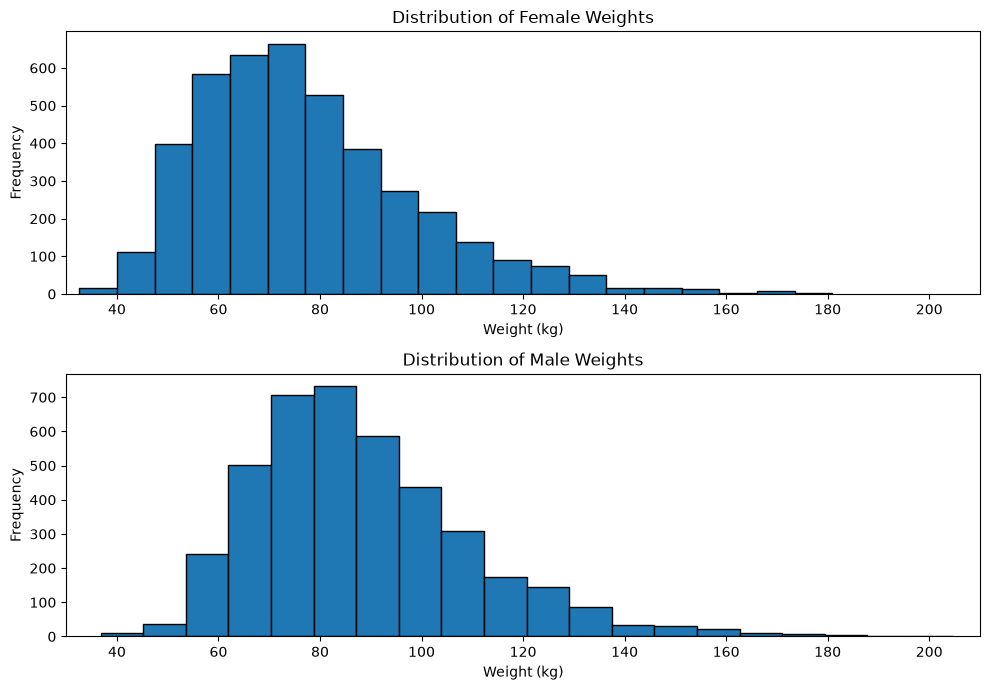

In [2]:
female_weights = female[:, 0]
male_weights = male[:, 0]

# Shared limits make the two histograms directly comparable
all_weights = np.concatenate((female_weights, male_weights))
xmin = np.floor(np.min(all_weights) / 10) * 10
xmax = np.ceil(np.max(all_weights) / 10) * 10

plt.figure(figsize=(10, 7))

plt.subplot(2, 1, 1)
plt.hist(female_weights, bins=20, edgecolor="black")
plt.xlim(xmin, xmax)
plt.title("Distribution of Female Weights")
plt.xlabel("Weight (kg)")
plt.ylabel("Frequency")

plt.subplot(2, 1, 2)
plt.hist(male_weights, bins=20, edgecolor="black")
plt.xlim(xmin, xmax)
plt.title("Distribution of Male Weights")
plt.xlabel("Weight (kg)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

**Results and discussion.** Compare the centres, widths, and tails of the two histograms. A distribution shifted to the right has generally higher weights; a wider distribution has greater variability. The common x-axis is important because it prevents differences in axis scaling from misleading the comparison.

## 3. Compare weights with box-and-whisker plots

A boxplot summarises each distribution using its median, quartiles, and potential outliers. The two boxes are placed side by side for a direct comparison.

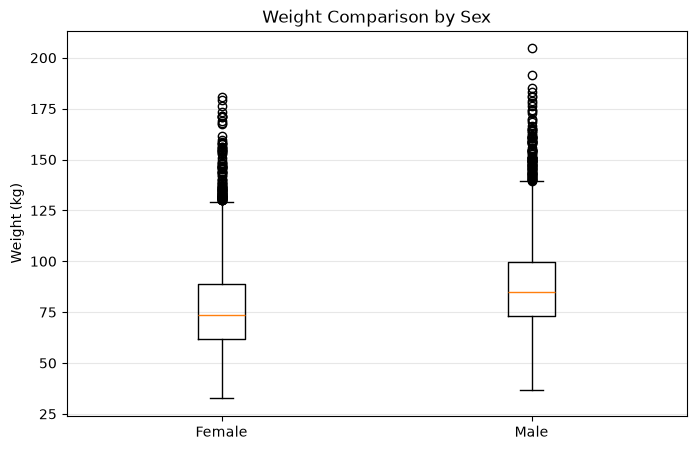

In [11]:
# 2. Compare weight distributions with boxplots

plt.figure(figsize=(8, 5))

plt.boxplot(
    [female_weights, male_weights],
    tick_labels=["Female", "Male"],
    showfliers=True
)

plt.ylabel("Weight (kg)")
plt.title("Weight Comparison by Sex")
plt.grid(axis="y", alpha=0.3)

plt.show()

**Results and discussion.** The line inside each box is the median, and the box spans the 25th to 75th percentiles. Whiskers show the range under the boxplot convention, while individual points beyond them are potential outliers. Compare the medians and interquartile ranges (box heights) to assess differences in typical weight and variability.

## 4. Numerical summaries of weight

The following code calculates measures of location (mean and median), dispersion (standard deviation, variance, range, and interquartile range), and shape (skewness and excess kurtosis). Skewness and kurtosis are calculated with pandas.

In [12]:
def weight_summary(values, label):
    s = pd.Series(values)
    return pd.Series({
        "Count": s.count(),
        "Mean (kg)": s.mean(),
        "Median (kg)": s.median(),
        "Minimum (kg)": s.min(),
        "Maximum (kg)": s.max(),
        "Range (kg)": s.max() - s.min(),
        "Variance (kg²)": s.var(),
        "Standard deviation (kg)": s.std(),
        "First quartile (kg)": s.quantile(0.25),
        "Third quartile (kg)": s.quantile(0.75),
        "Interquartile range (kg)": s.quantile(0.75) - s.quantile(0.25),
        "Skewness": s.skew(),
        "Excess kurtosis": s.kurt()
    }, name=label)

weight_stats = pd.concat([
    weight_summary(female_weights, "Female"),
    weight_summary(male_weights, "Male")
], axis=1)

display(weight_stats.round(3))

,Female,Male
Count,4221.000,4081.000
Mean (kg),77.404,88.365
Median (kg),73.600,85.000
Minimum (kg),32.600,36.800
Maximum (kg),180.900,204.600
Range (kg),148.300,167.800
Variance (kg²),464.190,458.883
Standard deviation (kg),21.545,21.422
First quartile (kg),61.600,73.300
Third quartile (kg),88.700,99.800


**Results and discussion.** Use the table to compare the average and median weights, then compare standard deviations and interquartile ranges to judge dispersion. Positive skewness indicates a longer right tail; negative skewness indicates a longer left tail. Skewness near zero suggests approximate symmetry, although it does not prove that a distribution is normal. Excess kurtosis is measured relative to a normal distribution, whose excess kurtosis is zero.

## 5. Add body mass index (BMI) to the female matrix

BMI is calculated as weight in kilograms divided by height in metres squared. Since height is stored in centimetres, it must be converted to metres before squaring. The BMI values are appended as an eighth column.

In [13]:
female_height_m = female[:, 1] / 100
female_bmi = female[:, 0] / (female_height_m ** 2)

female = np.column_stack((female, female_bmi))
column_names = column_names + ["BMI (kg/m²)"]

print("Updated female matrix shape:", female.shape)
print("First five BMI values:", female[:5, 7])

Updated female matrix shape: (4221, 8)
First five BMI values: [37.83504078 39.06972037 28.09265496 24.90437849 23.17879132]


**Results and discussion.** The female matrix should now have eight columns, with BMI in column index 7. BMI combines weight and height into a single size-for-height measure, but it does not directly distinguish fat mass from muscle mass or describe where body fat is stored.

## 6. Standardise the female measurements

A z-score expresses a value in standard deviations from its column mean. Each column is standardised independently using its mean and population standard deviation. The result is stored in `zfemale`, leaving the original measurements in `female` unchanged.

In [14]:
female_means = np.mean(female, axis=0)
female_stds = np.std(female, axis=0, ddof=0)

# Guard against division by zero in any constant column
female_stds_safe = np.where(female_stds == 0, 1, female_stds)
zfemale = (female - female_means) / female_stds_safe

print("Standardised matrix shape:", zfemale.shape)
print("Column means (approximately zero):", np.round(zfemale.mean(axis=0), 6))
print("Column standard deviations (approximately one):", np.round(zfemale.std(axis=0), 6))

Standardised matrix shape: (4221, 8)
Column means (approximately zero): [-0.  0.  0.  0.  0.  0. -0.  0.]
Column standard deviations (approximately one): [1. 1. 1. 1. 1. 1. 1. 1.]


**Results and discussion.** The means of the standardised columns should be approximately zero and their standard deviations approximately one. Small numerical differences can arise from floating-point rounding. Standardisation places measurements recorded in different units on a comparable scale, but it does not make their distributions normal.

## 7. Female scatterplot matrix and correlations

This section uses the standardised versions of height, weight, waist circumference, hip circumference, and BMI. A pairplot shows pairwise relationships, while Pearson and Spearman coefficients quantify linear and monotonic associations, respectively.

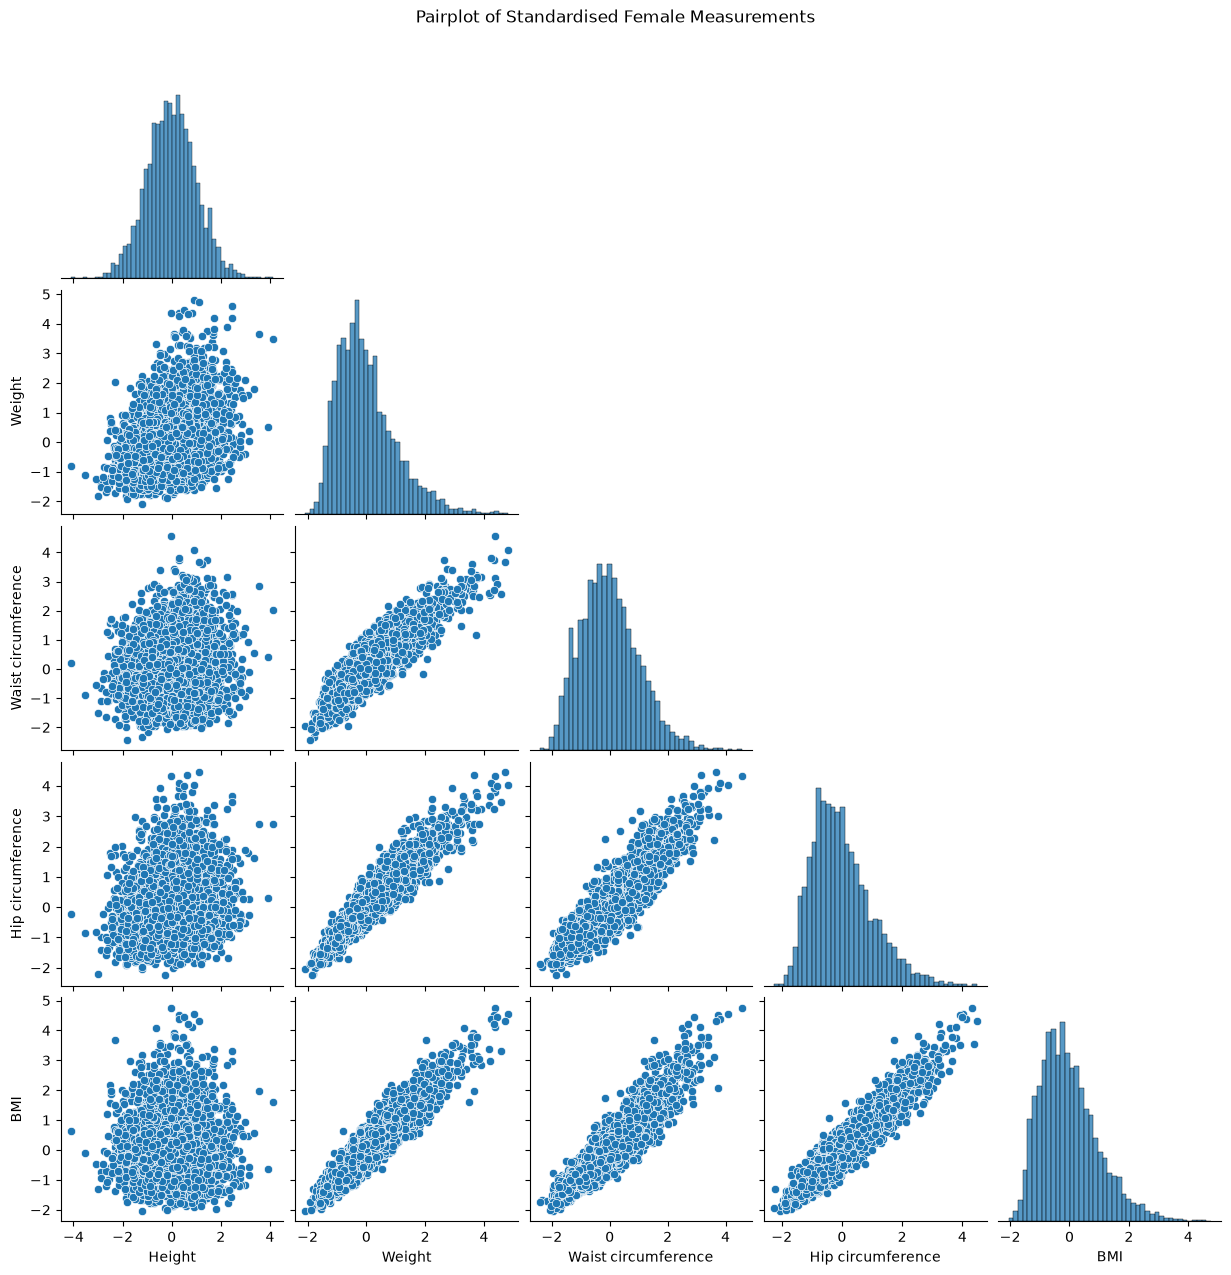

Pearson correlation matrix:


,Height,Weight,Waist circumference,Hip circumference,BMI
Height,1.000,0.345,0.127,0.203,0.033
Weight,0.345,1.000,0.905,0.947,0.946
Waist circumference,0.127,0.905,1.000,0.897,0.921
Hip circumference,0.203,0.947,0.897,1.000,0.944
BMI,0.033,0.946,0.921,0.944,1.000


Spearman correlation matrix:


,Height,Weight,Waist circumference,Hip circumference,BMI
Height,1.000,0.339,0.109,0.205,0.020
Weight,0.339,1.000,0.900,0.947,0.938
Waist circumference,0.109,0.900,1.000,0.888,0.923
Hip circumference,0.205,0.947,0.888,1.000,0.934
BMI,0.020,0.938,0.923,0.934,1.000


In [15]:
# Original female column indexes: weight=0, height=1, hip=5, waist=6, BMI=7
selected_indices = [1, 0, 6, 5, 7]
selected_names = ["Height", "Weight", "Waist circumference", "Hip circumference", "BMI"]

pair_data = pd.DataFrame(zfemale[:, selected_indices], columns=selected_names)

sns.pairplot(pair_data, diag_kind="hist", corner=True)
plt.suptitle("Pairplot of Standardised Female Measurements", y=1.02)
plt.show()

pearson_corr = pair_data.corr(method="pearson")
spearman_corr = pair_data.corr(method="spearman")

print("Pearson correlation matrix:")
display(pearson_corr.round(3))
print("Spearman correlation matrix:")
display(spearman_corr.round(3))

**Results and discussion.** Correlation coefficients range from −1 to +1. Values near +1 indicate a strong positive association; values near −1 indicate a strong negative association; values near zero indicate little linear (Pearson) or monotonic (Spearman) association. Pearson correlation is sensitive to outliers and measures linear relationships, whereas Spearman correlation uses ranks and can capture monotonic relationships that are not linear. Waist, hip, and BMI may be positively associated because they partly reflect body size; height may show a weaker relationship with circumferences. Report the actual coefficients from the matrices rather than assuming that any relationship is strong. Correlation does not establish causation.

## 8. Add waist-to-height and waist-to-hip ratios

The waist-to-height ratio (WHtR) is waist circumference divided by height; the waist-to-hip ratio (WHR) is waist circumference divided by hip circumference. Because both measurements in each ratio use the same units, centimetres cancel out. The two ratios are appended to both matrices.

In [16]:
# Original columns: height=1, hip=5, waist=6
male_whtr = male[:, 6] / male[:, 1]
male_whr = male[:, 6] / male[:, 5]
female_whtr = female[:, 6] / female[:, 1]
female_whr = female[:, 6] / female[:, 5]

male = np.column_stack((male, male_whtr, male_whr))
female = np.column_stack((female, female_whtr, female_whr))

print("Updated male matrix shape:", male.shape)
print("Updated female matrix shape:", female.shape)
print("Male first five WHtR values:", np.round(male[:5, 7], 3))
print("Male first five WHR values:", np.round(male[:5, 8], 3))
print("Female first five WHtR values:", np.round(female[:5, 8], 3))
print("Female first five WHR values:", np.round(female[:5, 9], 3))

Updated male matrix shape: (4081, 9)
Updated female matrix shape: (4221, 10)
Male first five WHtR values: [0.66  0.471 0.591 0.645 0.589]
Male first five WHR values: [1.113 0.919 1.017 1.018 0.89 ]
Female first five WHtR values: [0.736 0.675 0.571 0.575 0.473]
Female first five WHR values: [0.935 0.822 0.866 0.896 0.791]


**Results and discussion.** The male matrix should now have nine columns, while the female matrix should have ten columns because BMI was added earlier. The ratios are dimensionless. They describe body proportions rather than absolute body size, although they still do not directly measure body fat or diagnose a health condition.

## 9. Compare waist-based ratios

The boxplot below compares four groups: male waist-to-height ratio, female waist-to-height ratio, male waist-to-hip ratio, and female waist-to-hip ratio.

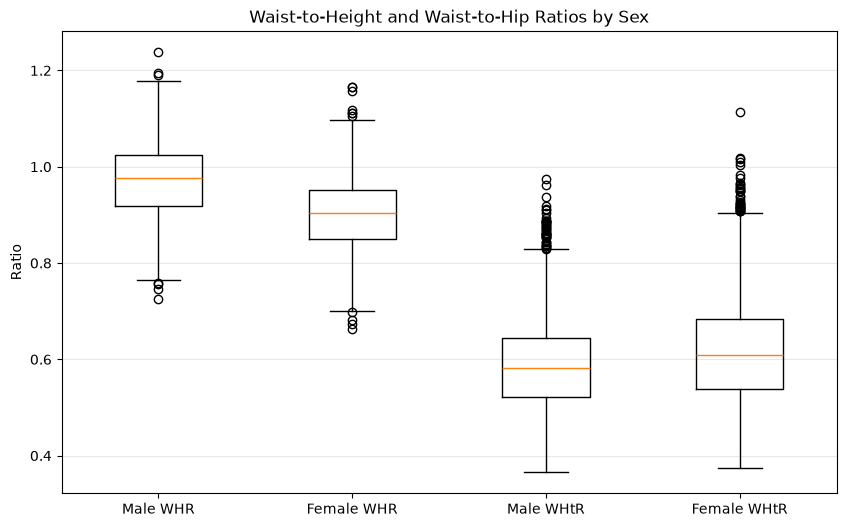

In [3]:
# 9. Compare waist-to-height and waist-to-hip ratios

# Correct column indices
# Weight = 0, Height = 1, Hip = 5, Waist = 6

male_whtr = male[:, 6] / male[:, 1]
female_whtr = female[:, 6] / female[:, 1]

male_whr = male[:, 6] / male[:, 5]
female_whr = female[:, 6] / female[:, 5]

# Plot the four groups
plt.figure(figsize=(10, 6))

plt.boxplot(
    [male_whr, female_whr, male_whtr, female_whtr],
    tick_labels=[
        "Male WHR",
        "Female WHR",
        "Male WHtR",
        "Female WHtR"
    ],
    showfliers=True
)

plt.ylabel("Ratio")
plt.title("Waist-to-Height and Waist-to-Hip Ratios by Sex")
plt.grid(axis="y", alpha=0.3)

plt.show()

**Results and discussion.** Compare the medians, interquartile ranges, and outliers for each group. Do not compare the absolute magnitudes of WHtR and WHR as though they were the same metric: each ratio has a different denominator and interpretation. Instead, compare male and female distributions within each ratio and note any differences in spread or potential outliers.

## 10. Advantages and limitations of BMI, WHtR, and WHR

The following points summarise practical strengths and limitations of the three measures.

- **BMI**
  - **Advantages:** Easy and inexpensive to calculate; requires only height and weight; useful for screening and population-level comparisons.
  - **Limitations:** Does not distinguish fat from muscle or bone; does not show fat distribution; interpretation can vary with age and other population characteristics.
- **Waist-to-height ratio (WHtR)**
  - **Advantages:** Includes waist size relative to height; offers a simple indicator of central body size; easy to calculate from two measurements.
  - **Limitations:** Depends on accurate waist and height measurements; cut-offs may vary by population and clinical context; is not a direct measurement of body fat.
- **Waist-to-hip ratio (WHR)**
  - **Advantages:** Relates waist circumference to hip circumference and gives information about body shape and fat distribution.
  - **Limitations:** Requires two circumference measurements; measurement technique can affect results; a ratio can change because either the waist or hip measurement changes.

**Interpretation note:** These indices are screening measures, not standalone diagnoses. Health assessment should consider clinical context and professional guidance.

## 11. Inspect the five lowest and five highest BMI participants

The final analysis sorts female participants by BMI and selects the five smallest and five largest values. It prints their standardised measurements, including standardised BMI, so the rows can be compared across variables. `argsort` returns the row indices in ascending BMI order.

In [20]:
# BMI is column index 7 in both female and zfemale at this point
bmi_order = np.argsort(female[:, 7])
lowest_bmi_rows = bmi_order[:5]
highest_bmi_rows = bmi_order[-5:][::-1]
chosen_rows = np.concatenate((lowest_bmi_rows, highest_bmi_rows))

standardised_columns = [
    "Weight z-score", "Height z-score", "Upper arm length z-score",
    "Upper leg length z-score", "Arm circumference z-score",
    "Hip circumference z-score", "Waist circumference z-score", "BMI z-score"
]

selected_zfemale = pd.DataFrame(zfemale[chosen_rows, :], columns=standardised_columns)
selected_zfemale.insert(0, "Participant row (0-based)", chosen_rows)
selected_zfemale.insert(1, "Group", ["Lowest BMI"] * 5 + ["Highest BMI"] * 5)

print("Five participants with the lowest BMI:")
display(selected_zfemale.iloc[:5].round(3))

print("Five participants with the highest BMI:")
display(selected_zfemale.iloc[5:].round(3))

Five participants with the lowest BMI:


,Participant row (0-based),Group,Weight z-score,Height z-score,Upper arm length z-score,Upper leg length z-score,Arm circumference z-score,Hip circumference z-score,Waist circumference z-score,BMI z-score
0,262,Lowest BMI,-2.080,-1.223,-1.548,-1.169,-2.195,-2.041,-1.942,-2.050
1,3478,Lowest BMI,-1.880,-0.189,-1.718,0.386,-2.444,-1.855,-2.057,-1.995
2,2126,Lowest BMI,-1.537,1.807,0.626,0.573,-2.266,-1.676,-1.706,-1.971
3,2753,Lowest BMI,-1.843,-0.260,-0.226,0.511,-2.302,-2.252,-1.856,-1.942
4,1209,Lowest BMI,-1.611,0.887,-0.098,0.480,-2.213,-1.829,-1.712,-1.893


Five participants with the highest BMI:


,Participant row (0-based),Group,Weight z-score,Height z-score,Upper arm length z-score,Upper leg length z-score,Arm circumference z-score,Hip circumference z-score,Waist circumference z-score,BMI z-score
5,1096,Highest BMI,4.363,-0.034,-0.056,-0.174,2.779,4.316,4.570,4.762
6,1104,Highest BMI,4.804,0.887,2.118,1.817,3.778,4.021,4.082,4.543
7,1472,Highest BMI,4.349,0.278,2.843,1.942,4.366,3.919,3.754,4.515
8,3022,Highest BMI,4.456,0.505,1.692,-1.138,3.350,3.983,2.903,4.462
9,2268,Highest BMI,4.247,0.292,1.862,-0.982,2.369,4.104,3.817,4.396


**Results and discussion.** Participants in the lowest-BMI group should have negative BMI z-scores relative to the female sample mean, while those in the highest-BMI group should have positive BMI z-scores. Review their weight, height, waist, and hip z-scores to see which measurements differ from the sample average. A negative z-score means below the sample mean and a positive z-score means above it. The selected rows are identified by zero-based row position, not by personal identity. Extreme BMI values alone are not enough to diagnose an individual's health status.

## 12. Conclusion

This notebook used NumPy matrices to load and extend the NHANES body-measurement excerpts, Matplotlib to compare distributions, and pandas/seaborn to summarise statistics and pairwise associations. Histograms and boxplots highlighted distributional differences; numerical summaries described location, dispersion, and shape; standardisation enabled measurements in different units to be compared; and BMI and waist-based ratios provided complementary views of body size and proportions.

**Final reporting reminder:** After running every cell, review the actual plots and numerical outputs and update any descriptive statements so that they accurately reflect the results produced by your downloaded data. These analyses are descriptive and should not be interpreted as medical diagnoses.